In [1]:
# ==============================================================================
# 1. IMPORTACIÓN DE LIBRERÍAS
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ajustes de estilo para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

In [2]:
# ==============================================================================
# 2. CARGA DE DATOS Y VISUALIZACIÓN INICIAL
# ==============================================================================
# Carga del fichero CSV con los datos de viviendas de Ames
datos = pd.read_csv("data.csv")

# Visualizamos las primeras filas
display(datos.head())

# Tipos de datos de las columnas
print("Tipos de datos de las columnas:")
print(datos.dtypes)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Tipos de datos de las columnas:
Id                 int64
MSSubClass         int64
MSZoning             str
LotFrontage      float64
LotArea            int64
                  ...   
MoSold             int64
YrSold             int64
SaleType             str
SaleCondition        str
SalePrice          int64
Length: 81, dtype: object


In [3]:
# ==============================================================================
# 3. NÚMERO DE VIVIENDAS Y RECUENTO DE VALORES NULOS
# ==============================================================================
# Número total de viviendas en el conjunto de datos
total_viviendas = datos.shape[0]
print(f"Total de viviendas (observaciones): {total_viviendas}")

# Variables con valores nulos y recuento ordenado de mayor a menor
recuento_nulos = datos.isnull().sum()
variables_con_nulos = recuento_nulos[recuento_nulos > 0].sort_values(ascending=False)

print("\nVariables con valores nulos:")
print(variables_con_nulos)

Total de viviendas (observaciones): 1460

Variables con valores nulos:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [4]:
# ==============================================================================
# 4. ANÁLISIS INDIVIDUAL DE VARIABLES (LOTE 1: Id, MSSubClass, MSZoning)
# ==============================================================================
variables_lote1 = ['Id', 'MSSubClass', 'MSZoning']

for columna in variables_lote1:
    print(f"--- Análisis de {columna} ---")
    print(f"Tipo actual: {datos[columna].dtype}")
    print(f"Valores nulos: {datos[columna].isnull().sum()}")
    print(f"Número de valores únicos: {datos[columna].nunique()}")
    print(f"Primeros valores únicos: {datos[columna].unique()[:8]}")
    
    if pd.api.types.is_numeric_dtype(datos[columna]):
        print(f"Mínimo: {datos[columna].min()} | Máximo: {datos[columna].max()}")
    else:
        print(f"Frecuencia de categorías:\n{datos[columna].value_counts()}")
    print("\n")

# Reflexión sobre las variables del Lote 1:
# - Id: Numérica discreta (identificador). Mín: 1, Máx: 1460. Sin nulos. No hay outliers con significado real.
#   Decisión: Eliminar porque es un simple identificador y no aporta poder predictivo sobre la vivienda.
# - MSSubClass: Categórica nominal sin orden (codificada con números: 20, 30, 60... según data-description.txt).
#   Sin nulos. Decisión: Recodificar a string (objeto) para que los modelos no asuman relaciones aritméticas falsas.
# - MSZoning: Categórica nominal sin orden (RL, RM, C, FV, RH). Sin nulos.
#   Decisión: Conservar (en fases de modelado posterior requerirá One-Hot Encoding).

--- Análisis de Id ---
Tipo actual: int64
Valores nulos: 0
Número de valores únicos: 1460
Primeros valores únicos: [1 2 3 4 5 6 7 8]
Mínimo: 1 | Máximo: 1460


--- Análisis de MSSubClass ---
Tipo actual: int64
Valores nulos: 0
Número de valores únicos: 15
Primeros valores únicos: [ 60  20  70  50 190  45  90 120]
Mínimo: 20 | Máximo: 190


--- Análisis de MSZoning ---
Tipo actual: str
Valores nulos: 0
Número de valores únicos: 5
Primeros valores únicos: <StringArray>
['RL', 'RM', 'C (all)', 'FV', 'RH']
Length: 5, dtype: str
Frecuencia de categorías:
MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64




In [5]:
# Aplicamos las decisiones del análisis del Lote 1

# 1. Eliminamos la columna 'Id' ya que no aporta poder predictivo
datos = datos.drop('Id', axis=1)

# 2. Recodificamos 'MSSubClass' a tipo string/object para que no sea tratada como numérica
datos['MSSubClass'] = datos['MSSubClass'].astype(str)

# Comprobamos los cambios
print("¿Sigue 'Id' en columnas?:", 'Id' in datos.columns)
print("Tipo actual de 'MSSubClass':", datos['MSSubClass'].dtype)

¿Sigue 'Id' en columnas?: False
Tipo actual de 'MSSubClass': str


In [6]:
# ==============================================================================
# 4. ANÁLISIS INDIVIDUAL DE VARIABLES (LOTE 2: LotFrontage, LotArea, Street, Alley, LotShape)
# ==============================================================================
variables_lote2 = ['LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape']

for columna in variables_lote2:
    print(f"--- Análisis de {columna} ---")
    print(f"Tipo actual: {datos[columna].dtype}")
    print(f"Valores nulos: {datos[columna].isnull().sum()}")
    print(f"Número de valores únicos: {datos[columna].nunique()}")
    print(f"Primeros valores únicos: {datos[columna].unique()[:6]}")
    
    if pd.api.types.is_numeric_dtype(datos[columna]):
        print(f"Mínimo: {datos[columna].min()} | Máximo: {datos[columna].max()} | Mediana: {datos[columna].median()}")
    else:
        print(f"Frecuencia de categorías:\n{datos[columna].value_counts(dropna=False)}")
    print("\n")

# Reflexión sobre las variables del Lote 2:
# - LotFrontage: Numérica continua (longitud lineal de calle conectada a la parcela). 259 nulos (17.7%).
#   Mín 21, Máx 313, Mediana 69. Presenta outliers hacia valores altos.
#   Tratamiento: Imputar nulos con la mediana (robusta frente a valores atípicos). Decisión: Conservar.
# - LotArea: Numérica continua (superficie del lote en pies cuadrados). 0 nulos.
#   Mín 1300, Máx 215245, Mediana 9478.5. Presenta fuerte asimetría positiva con outliers extremos (> 50.000 sq ft).
#   Decisión: Conservar (variable clave; conviene aplicar transformación logarítmica en regresión).
# - Street: Categórica nominal sin orden (Pave: 1454, Grvl: 6). 0 nulos.
#   Varianza prácticamente nula (el 99.6% es Pave). Decisión: Conservar por completitud.
# - Alley: Categórica nominal sin orden (Grvl, Pave o NA). 1369 nulos (93.8%).
#   Según data-description.txt, NA significa 'No alley access'.
#   Tratamiento: Imputar nulos con la categoría 'Sin_Acceso'. Decisión: Conservar.
# - LotShape: Categórica ordinal con orden (Reg, IR1, IR2, IR3). 0 nulos.
#   Decisión: Conservar (en fases de modelado puede mapearse a escala numérica 0, 1, 2, 3).

--- Análisis de LotFrontage ---
Tipo actual: float64
Valores nulos: 259
Número de valores únicos: 110
Primeros valores únicos: [65. 80. 68. 60. 84. 85.]
Mínimo: 21.0 | Máximo: 313.0 | Mediana: 69.0


--- Análisis de LotArea ---
Tipo actual: int64
Valores nulos: 0
Número de valores únicos: 1073
Primeros valores únicos: [ 8450  9600 11250  9550 14260 14115]
Mínimo: 1300 | Máximo: 215245 | Mediana: 9478.5


--- Análisis de Street ---
Tipo actual: str
Valores nulos: 0
Número de valores únicos: 2
Primeros valores únicos: <StringArray>
['Pave', 'Grvl']
Length: 2, dtype: str
Frecuencia de categorías:
Street
Pave    1454
Grvl       6
Name: count, dtype: int64


--- Análisis de Alley ---
Tipo actual: str
Valores nulos: 1369
Número de valores únicos: 2
Primeros valores únicos: <StringArray>
[nan, 'Grvl', 'Pave']
Length: 3, dtype: str
Frecuencia de categorías:
Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64


--- Análisis de LotShape ---
Tipo actual: str
Valores nulos: 0
Nú

In [7]:
# Aplicamos las decisiones del análisis del Lote 2

# 1. Tratamiento de nulos en 'LotFrontage': Imputamos con la mediana
mediana_lot_frontage = datos['LotFrontage'].median()
datos['LotFrontage'] = datos['LotFrontage'].fillna(mediana_lot_frontage)

# 2. Tratamiento de nulos en 'Alley': Reemplazamos los NaN (que significan "No alley") por el texto 'Sin_Acceso'
datos['Alley'] = datos['Alley'].fillna('Sin_Acceso')

# Comprobamos que ya no hay nulos en estas variables
print("Nulos restantes en LotFrontage:", datos['LotFrontage'].isnull().sum())
print("Nulos restantes en Alley:", datos['Alley'].isnull().sum())

Nulos restantes en LotFrontage: 0
Nulos restantes en Alley: 0


In [8]:
# ==============================================================================
# 4. ANÁLISIS INDIVIDUAL DE VARIABLES (LOTE 3: LandContour, Utilities, LandSlope, Neighborhood)
# ==============================================================================
variables_lote3 = ['LandContour', 'Utilities', 'LandSlope', 'Neighborhood']

for columna in variables_lote3:
    print(f"--- Análisis de {columna} ---")
    print(f"Tipo actual: {datos[columna].dtype}")
    print(f"Valores nulos: {datos[columna].isnull().sum()}")
    print(f"Número de valores únicos: {datos[columna].nunique()}")
    print(f"Frecuencia de valores:\n{datos[columna].value_counts()}")
    print("\n")

# Reflexión sobre las variables del Lote 3:
# - LandContour: Categórica nominal sin orden (Lvl: 89.8%, Bnk, HLS, Low). 0 nulos. Decisión: Conservar.
# - Utilities: Categórica nominal/ordinal (AllPub: 1459, NoSeWa: 1). 0 nulos.
#   Varianza prácticamente nula (solo 1 valor distinto en 1460 filas).
#   Decisión: ELIMINAR, ya que no aporta poder predictivo y genera ruido inútil.
# - LandSlope: Categórica ordinal con orden (Gtl: 94.7%, Mod, Sev). 0 nulos.
#   Decisión: Conservar (o binarizar en llano vs pendiente).
# - Neighborhood: Categórica nominal sin orden (25 barrios). 0 nulos.
#   Decisión: Conservar indispensablemente (esencial para el precio de la vivienda; requerirá One-Hot Encoding).

--- Análisis de LandContour ---
Tipo actual: str
Valores nulos: 0
Número de valores únicos: 4
Frecuencia de valores:
LandContour
Lvl    1311
Bnk      63
HLS      50
Low      36
Name: count, dtype: int64


--- Análisis de Utilities ---
Tipo actual: str
Valores nulos: 0
Número de valores únicos: 2
Frecuencia de valores:
Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64


--- Análisis de LandSlope ---
Tipo actual: str
Valores nulos: 0
Número de valores únicos: 3
Frecuencia de valores:
LandSlope
Gtl    1382
Mod      65
Sev      13
Name: count, dtype: int64


--- Análisis de Neighborhood ---
Tipo actual: str
Valores nulos: 0
Número de valores únicos: 25
Frecuencia de valores:
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
StoneBr     25
SWISU       25
Meadow

In [9]:
# Aplicamos las decisiones del análisis del Lote 3

# Eliminamos la columna 'Utilities' debido a que tiene varianza casi nula (1459 AllPub vs 1 NoSeWa)
datos = datos.drop('Utilities', axis=1)

print("¿Sigue 'Utilities' en columnas?:", 'Utilities' in datos.columns)

¿Sigue 'Utilities' en columnas?: False


In [10]:
# ==============================================================================
# 4. ANÁLISIS INDIVIDUAL DE VARIABLES (LOTE 4: Fechas - YearBuilt, YearRemodAdd)
# ==============================================================================
variables_lote4 = ['YearBuilt', 'YearRemodAdd']

for columna in variables_lote4:
    print(f"--- Análisis de {columna} ---")
    print(f"Tipo actual: {datos[columna].dtype}")
    print(f"Valores nulos: {datos[columna].isnull().sum()}")
    print(f"Mínimo: {datos[columna].min()} | Máximo: {datos[columna].max()} | Mediana: {datos[columna].median()}")
    print(f"Número de valores únicos: {datos[columna].nunique()}")
    print("\n")

# Comprobación de coherencia temporal (el año de reforma no puede ser anterior a la construcción)
inconsistencias_fechas = (datos['YearRemodAdd'] < datos['YearBuilt']).sum()
print(f"Casas con año de remodelación anterior a construcción: {inconsistencias_fechas}")

# Reflexión:
# - YearBuilt: Numérica discreta temporal (1872 - 2010). Mediana 1973. Sin nulos. Sin valores anómalos.
# - YearRemodAdd: Numérica discreta temporal (1950 - 2010). Mediana 1994. Sin nulos.
#   Si la casa no ha sido remodelada, toma el valor de YearBuilt.
# - Decisión: Conservar ambas intactas (fundamentales para el precio y permiten derivar la antigüedad).

--- Análisis de YearBuilt ---
Tipo actual: int64
Valores nulos: 0
Mínimo: 1872 | Máximo: 2010 | Mediana: 1973.0
Número de valores únicos: 112


--- Análisis de YearRemodAdd ---
Tipo actual: int64
Valores nulos: 0
Mínimo: 1950 | Máximo: 2010 | Mediana: 1994.0
Número de valores únicos: 61


Casas con año de remodelación anterior a construcción: 0


In [11]:
# ==============================================================================
# 4. ANÁLISIS INDIVIDUAL DE VARIABLES (LOTE 5: Garaje en conjunto)
# ==============================================================================
variables_garaje = ['GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'GarageType', 'GarageYrBlt', 'GarageFinish']

print("--- Resumen de variables de Garaje ---")
for columna in variables_garaje:
    nulos_columna = datos[columna].isnull().sum()
    tipo_columna = datos[columna].dtype
    unicos_columna = datos[columna].nunique()
    print(f"{columna:14} | Tipo: {str(tipo_columna):10} | Nulos: {nulos_columna:4} | Únicos: {unicos_columna:4}")
    if pd.api.types.is_numeric_dtype(datos[columna]):
        print(f"  -> Mínimo: {datos[columna].min()} | Máximo: {datos[columna].max()} | Mediana: {datos[columna].median()}")

# Comprobamos si las 81 observaciones con nulos corresponden exactamente a viviendas sin garaje
casas_sin_garaje = (datos['GarageCars'] == 0) & (datos['GarageArea'] == 0)
print(f"\nCasas con GarageCars == 0 y GarageArea == 0: {casas_sin_garaje.sum()}")
print(f"Casas con GarageType nulo: {datos['GarageType'].isnull().sum()}")

# Reflexión:
# - GarageQual, GarageCond, GarageFinish, GarageType: Categóricas (ordinales y nominales).
#   Tienen 81 nulos que significan 'No Garage' según data-description.txt.
#   Tratamiento: Imputar con 'Sin_Garaje'.
# - GarageYrBlt: Numérica discreta (año de construcción del garaje). Tiene 81 nulos (casas sin garaje).
#   Tratamiento: Imputar con 0 para indicar ausencia sin romper el tipo numérico.
# - GarageCars (0 a 4) y GarageArea (0 a 1418 sq ft): Numéricas discretas/continuas. Sin nulos.
#   Presentan correlación alta (multicolinealidad ~ 0.88). Decisión: Conservar ambas.

--- Resumen de variables de Garaje ---
GarageCars     | Tipo: int64      | Nulos:    0 | Únicos:    5
  -> Mínimo: 0 | Máximo: 4 | Mediana: 2.0
GarageArea     | Tipo: int64      | Nulos:    0 | Únicos:  441
  -> Mínimo: 0 | Máximo: 1418 | Mediana: 480.0
GarageQual     | Tipo: str        | Nulos:   81 | Únicos:    5
GarageCond     | Tipo: str        | Nulos:   81 | Únicos:    5
GarageType     | Tipo: str        | Nulos:   81 | Únicos:    6
GarageYrBlt    | Tipo: float64    | Nulos:   81 | Únicos:   97
  -> Mínimo: 1900.0 | Máximo: 2010.0 | Mediana: 1980.0
GarageFinish   | Tipo: str        | Nulos:   81 | Únicos:    3

Casas con GarageCars == 0 y GarageArea == 0: 81
Casas con GarageType nulo: 81


In [12]:
# Aplicamos las decisiones del análisis del Lote 5 (Garaje)

# 1. Rellenamos los 81 nulos de las variables categóricas del garaje con 'Sin_Garaje'
columnas_garaje_categoricas = ['GarageQual', 'GarageCond', 'GarageType', 'GarageFinish']
for columna in columnas_garaje_categoricas:
    datos[columna] = datos[columna].fillna('Sin_Garaje')

# 2. Rellenamos los nulos de GarageYrBlt con 0
datos['GarageYrBlt'] = datos['GarageYrBlt'].fillna(0)

# Comprobamos que no quedan nulos en las variables de garaje
print("Nulos restantes en variables de garaje:")
print(datos[variables_garaje].isnull().sum())

Nulos restantes en variables de garaje:
GarageCars      0
GarageArea      0
GarageQual      0
GarageCond      0
GarageType      0
GarageYrBlt     0
GarageFinish    0
dtype: int64


In [13]:
# ==============================================================================
# 4. ANÁLISIS INDIVIDUAL DE VARIABLES (LOTE 6: Calidades y Precio)
# ==============================================================================
variables_lote6 = ['OverallQual', 'OverallCond', 'SalePrice']

for columna in variables_lote6:
    print(f"--- Análisis de {columna} ---")
    print(f"Tipo actual: {datos[columna].dtype}")
    print(f"Valores nulos: {datos[columna].isnull().sum()}")
    print(f"Valores únicos ({datos[columna].nunique()}): {sorted(datos[columna].unique())[:10]}")
    print(f"Mínimo: {datos[columna].min()} | Máximo: {datos[columna].max()} | Mediana: {datos[columna].median()} | Media: {datos[columna].mean():.2f}")
    print("\n")

# Reflexión:
# - OverallQual: Categórica ordinal con orden (notas del 1 al 10). 0 nulos. Mediana 6. Es el predictor individual más potente.
# - OverallCond: Categórica ordinal con orden (notas del 1 al 10). 0 nulos. Mediana 5.
# - SalePrice: Numérica continua. Variable objetivo (target). 0 nulos. Mín 34.900 $, Máx 755.000 $, Mediana 163.000 $.
#   Presenta asimetría a la derecha (sesgo positivo) y outliers altos (> 500.000 $).
# - Decisión: Conservar las tres. SalePrice es la variable a predecir.

--- Análisis de OverallQual ---
Tipo actual: int64
Valores nulos: 0
Valores únicos (10): [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Mínimo: 1 | Máximo: 10 | Mediana: 6.0 | Media: 6.10


--- Análisis de OverallCond ---
Tipo actual: int64
Valores nulos: 0
Valores únicos (9): [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Mínimo: 1 | Máximo: 9 | Mediana: 5.0 | Media: 5.58


--- Análisis de SalePrice ---
Tipo actual: int64
Valores nulos: 0
Valores únicos (663): [np.int64(34900), np.int64(35311), np.int64(37900), np.int64(39300), np.int64(40000), np.int64(52000), np.int64(52500), np.int64(55000), np.int64(55993), np.int64(58500)]
Mínimo: 34900 | Máximo: 755000 | Mediana: 163000.0 | Media: 180921.20




In [14]:
# ==============================================================================
# 5. COMPROBACIONES ESTADÍSTICAS FINALES
# ==============================================================================

# 1. Comprobación del número de casas respecto a la pregunta 3
print(f"Número de casas inicial (pregunta 3): {total_viviendas}")
print(f"Número de casas actual: {datos.shape[0]}")
print(f"¿Ha variado el número de casas?: {'Sí' if datos.shape[0] != total_viviendas else 'No ha variado, sigue siendo 1460'}")

# 2. Tabla comparativa de valores nulos (antes vs actual)
tabla_comparativa_nulos = pd.DataFrame({
    'Columna': ['LotFrontage', 'Alley', 'Utilities', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageQual', 'GarageCond'],
    '#Missing values anteriores': [259, 1369, 0, 81, 81, 81, 81, 81],
    '#Missing values actual': [
        datos['LotFrontage'].isnull().sum(),
        datos['Alley'].isnull().sum(),
        "Eliminada",
        datos['GarageType'].isnull().sum(),
        datos['GarageYrBlt'].isnull().sum(),
        datos['GarageFinish'].isnull().sum(),
        datos['GarageQual'].isnull().sum(),
        datos['GarageCond'].isnull().sum()
    ]
})

print("\nTabla comparativa de nulos:")
display(tabla_comparativa_nulos)

Número de casas inicial (pregunta 3): 1460
Número de casas actual: 1460
¿Ha variado el número de casas?: No ha variado, sigue siendo 1460

Tabla comparativa de nulos:


,Columna,#Missing values anteriores,#Missing values actual
0,LotFrontage,259,0
1,Alley,1369,0
2,Utilities,0,Eliminada
3,GarageType,81,0
4,GarageYrBlt,81,0
5,GarageFinish,81,0
6,GarageQual,81,0
7,GarageCond,81,0


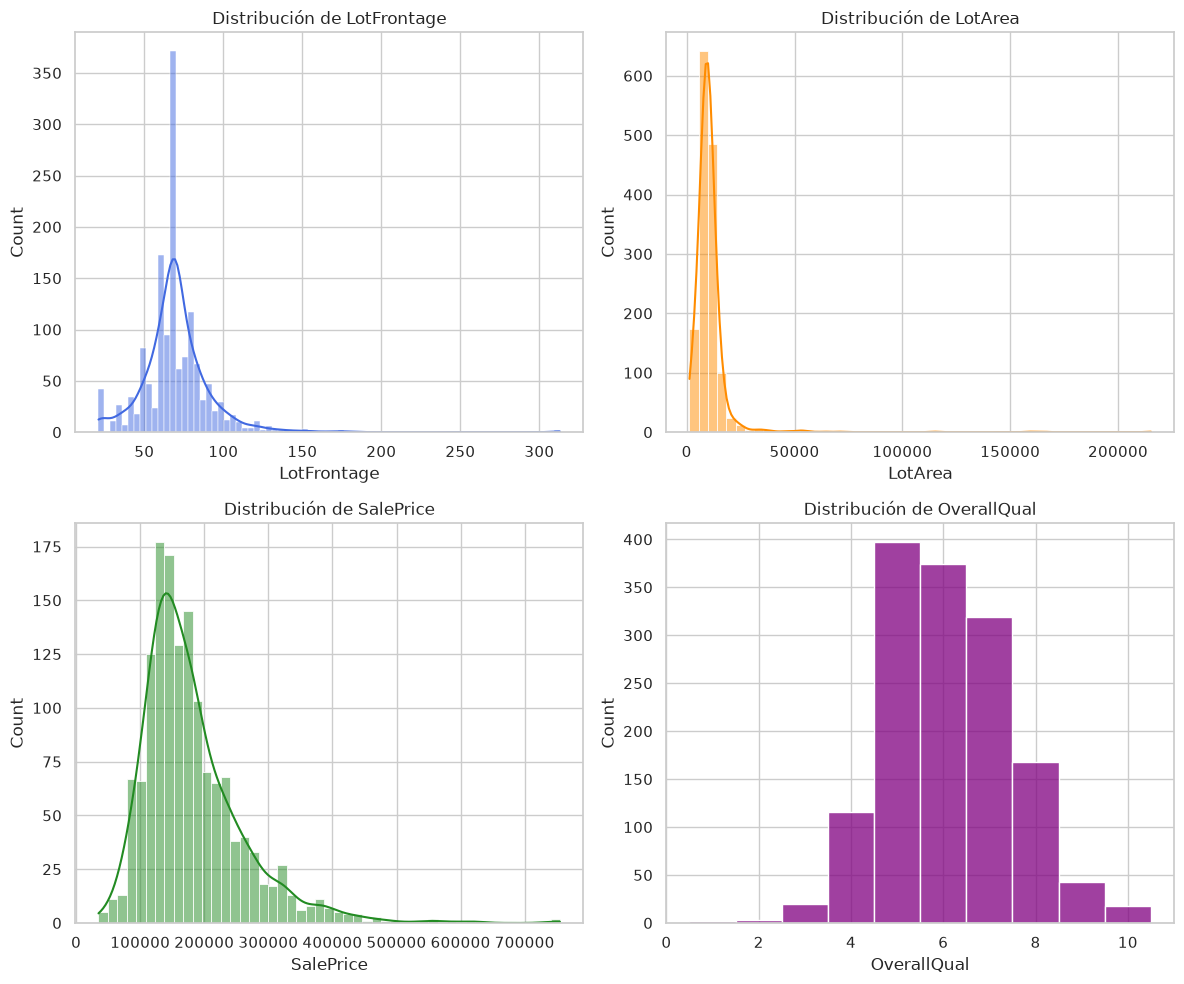

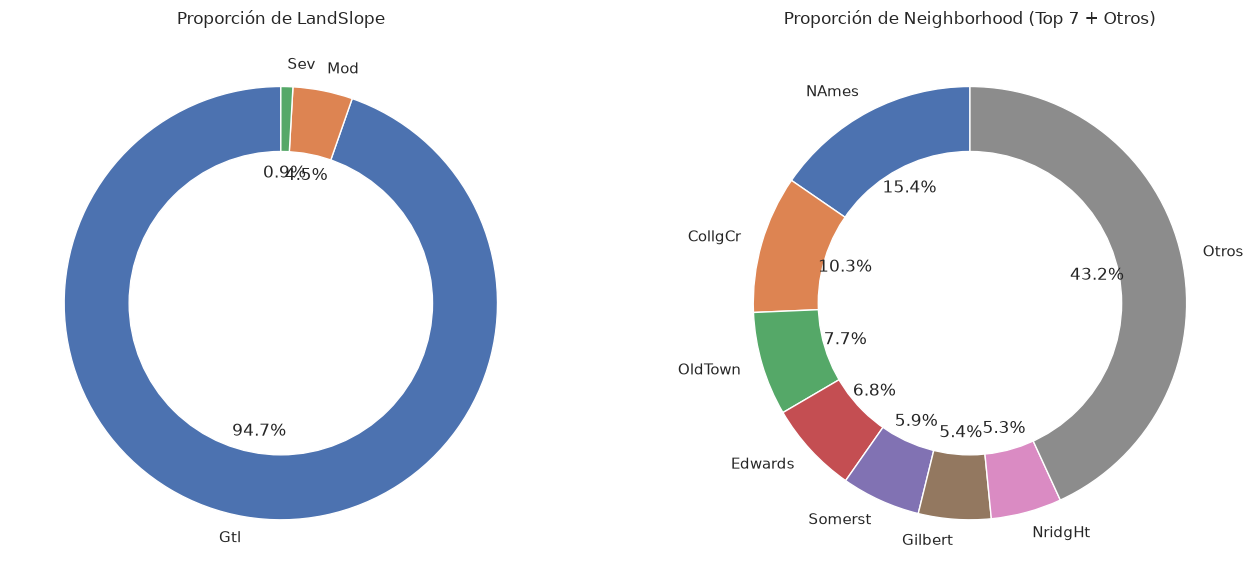

In [15]:
# ==============================================================================
# 6. GRÁFICOS DE DISTRIBUCIÓN Y TOMA DE DECISIONES
# ==============================================================================

# 1. Histogramas de LotFrontage, LotArea, SalePrice y OverallQual
figura_histogramas, ejes_histogramas = plt.subplots(2, 2, figsize=(12, 10))

sns.histplot(datos['LotFrontage'], kde=True, ax=ejes_histogramas[0, 0], color='royalblue')
ejes_histogramas[0, 0].set_title('Distribución de LotFrontage')

sns.histplot(datos['LotArea'], kde=True, bins=50, ax=ejes_histogramas[0, 1], color='darkorange')
ejes_histogramas[0, 1].set_title('Distribución de LotArea')

sns.histplot(datos['SalePrice'], kde=True, ax=ejes_histogramas[1, 0], color='forestgreen')
ejes_histogramas[1, 0].set_title('Distribución de SalePrice')

sns.histplot(datos['OverallQual'], discrete=True, ax=ejes_histogramas[1, 1], color='purple')
ejes_histogramas[1, 1].set_title('Distribución de OverallQual')

plt.tight_layout()
plt.show()

# 2. Gráficos de Donut para LandSlope y Neighborhood
figura_donuts, ejes_donuts = plt.subplots(1, 2, figsize=(14, 6))

# Donut LandSlope
frecuencias_land_slope = datos['LandSlope'].value_counts()
ejes_donuts[0].pie(frecuencias_land_slope, labels=frecuencias_land_slope.index, autopct='%1.1f%%', startangle=90)
circulo_centro_slope = plt.Circle((0, 0), 0.70, color='white')
ejes_donuts[0].add_artist(circulo_centro_slope)
ejes_donuts[0].set_title('Proporción de LandSlope')

# Donut Neighborhood (mostramos los 7 barrios mayoritarios y agrupamos el resto para garantizar legibilidad)
total_barrios_principales = 7
frecuencias_neighborhood = datos['Neighborhood'].value_counts()
barrios_principales = frecuencias_neighborhood[:total_barrios_principales]
barrios_otros = pd.Series({'Otros': frecuencias_neighborhood[total_barrios_principales:].sum()})
datos_donut_neighborhood = pd.concat([barrios_principales, barrios_otros])

ejes_donuts[1].pie(datos_donut_neighborhood, labels=datos_donut_neighborhood.index, autopct='%1.1f%%', startangle=90)
circulo_centro_neighborhood = plt.Circle((0, 0), 0.70, color='white')
ejes_donuts[1].add_artist(circulo_centro_neighborhood)
ejes_donuts[1].set_title('Proporción de Neighborhood (Top 7 + Otros)')

plt.tight_layout()
plt.show()

# ==============================================================================
# COMENTARIOS Y TOMA DE DECISIONES SOBRE ESTAS VARIABLES:
#
# 1. Histogramas:
#    - SalePrice: Asimetría positiva muy clara con cola larga a la derecha (precios de lujo).
#      Conviene aplicar log(SalePrice) para modelos de regresión lineal.
#    - LotArea: Fuerte concentración con outliers extremos (> 50000 sq ft). Requiere log o escalado robusto.
#    - LotFrontage: Distribución acampanada centrada en ~69 pies con ligera cola derecha.
#    - OverallQual: Distribución discreta unimodal centrada en 5 y 6.
#
# 2. Toma de decisiones sobre variables categóricas (LandSlope, Neighborhood, Utilities):
#    - LandSlope: El 94.7% de parcelas son 'Gtl' (Gentle). Debido a su baja varianza, apenas aporta
#      información diferenciadora; se puede binarizar ('Es_Llano': 1 si Gtl, 0 en otro caso) o valorar eliminarla.
#    - Neighborhood: Cuenta con 25 barrios diversos. Es un factor determinante en el valor del suelo y precio de venta.
#      Decisión: Conservar obligatoriamente; requiere One-Hot Encoding o Target Encoding.
#    - Utilities: Varianza prácticamente nula (1459 AllPub vs 1 NoSeWa) -> Decisión: Ya ha sido eliminada por completo.
# ==============================================================================


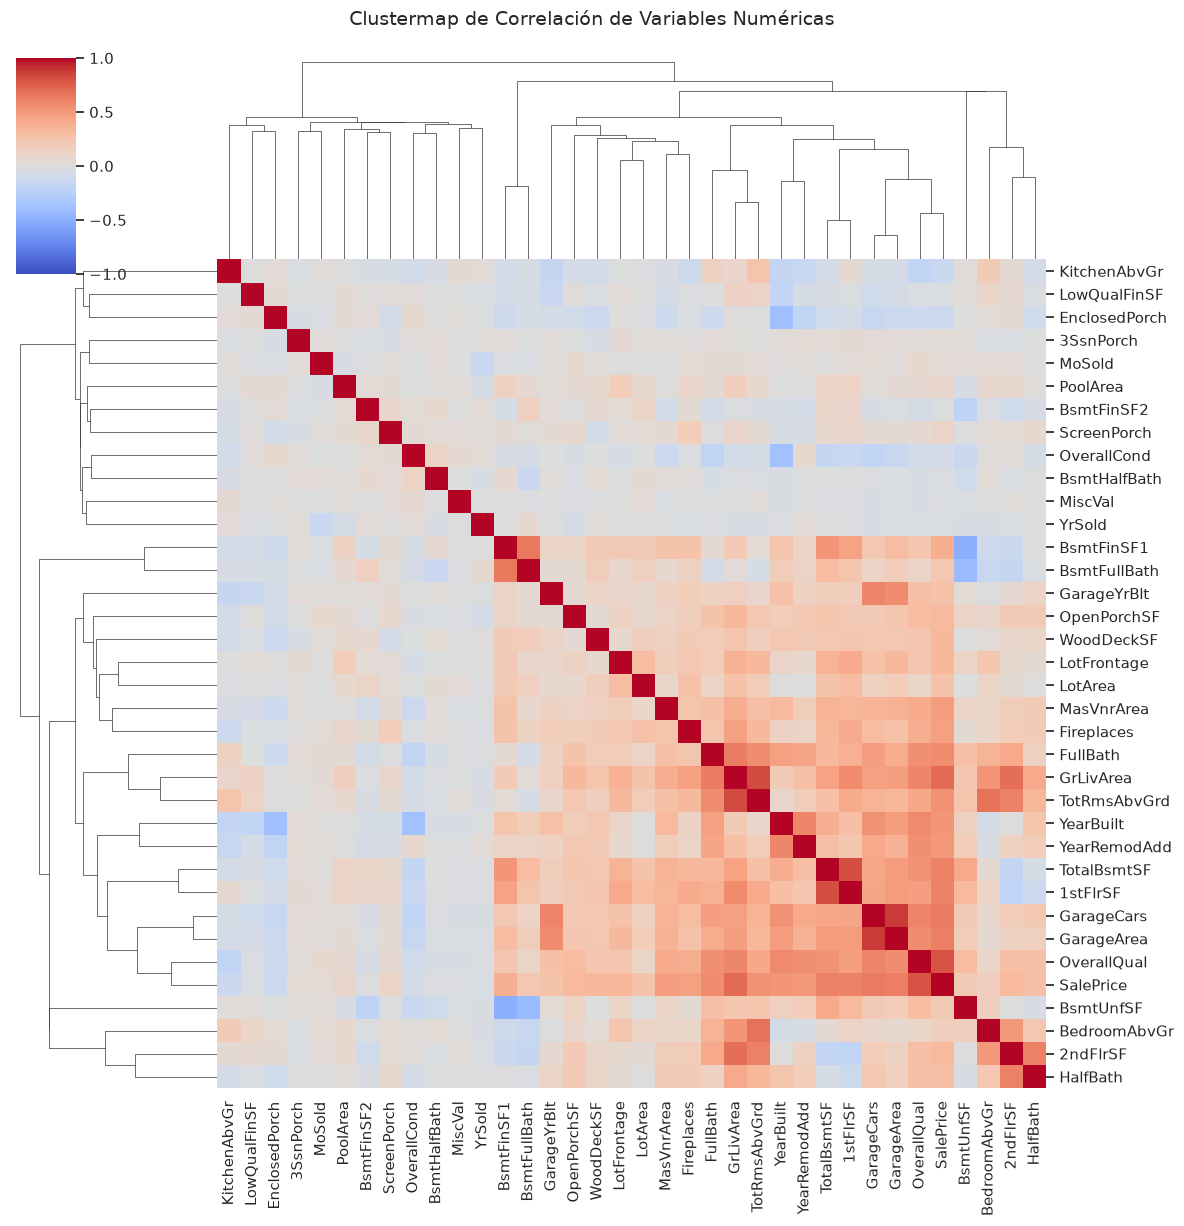

Top 10 variables numéricas con mayor correlación con SalePrice:
SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


In [16]:
# ==============================================================================
# 7. MATRIZ DE CORRELACIÓN Y CLUSTERMAP
# ==============================================================================

# Seleccionamos solo las variables numéricas del dataset tras el preprocesado
columnas_numericas = datos.select_dtypes(include=['int64', 'float64']).columns
matriz_correlacion = datos[columnas_numericas].corr()

# Dibujamos el clustermap con seaborn
grafico_clustermap = sns.clustermap(
    matriz_correlacion, 
    cmap='coolwarm', 
    figsize=(12, 12), 
    vmin=-1, vmax=1, 
    annot=False
)
grafico_clustermap.figure.suptitle("Clustermap de Correlación de Variables Numéricas", y=1.02, fontsize=14)
plt.show()

# Variables con mayor correlación con SalePrice
correlacion_precio = matriz_correlacion['SalePrice'].sort_values(ascending=False)
print("Top 10 variables numéricas con mayor correlación con SalePrice:")
print(correlacion_precio.head(11))

# ==============================================================================
# COMENTARIOS SOBRE LOS RESULTADOS DEL CLUSTERMAP:
#
# 1. Variables con mayor correlación positiva con SalePrice:
#    - OverallQual (0.79): La calidad global de acabados es el predictor individual más potente.
#    - GrLivArea (0.71): Superficie habitable sobre rasante.
#    - GarageCars (0.64) y GarageArea (0.62): Capacidad y tamaño del garaje.
#    - TotalBsmtSF (0.61) y 1stFlrSF (0.61): Superficie del sótano y de la primera planta.
#    - FullBath (0.56), TotRmsAbvGrd (0.53), YearBuilt (0.52) y YearRemodAdd (0.51).
#
# 2. Detección de Multicolinealidad (clusters correlacionados entre sí):
#    - GarageCars y GarageArea (r ~ 0.88): Miden prácticamente lo mismo sobre el garaje.
#    - TotalBsmtSF y 1stFlrSF (r ~ 0.82): La huella del sótano coincide con la primera planta.
#    - GrLivArea y TotRmsAbvGrd (r ~ 0.83): A mayor superficie habitable, mayor número de habitaciones.
#    - YearBuilt y GarageYrBlt: Fuertemente vinculadas cuando la casa tiene garaje.
#
# 3. Implicaciones para el modelado posterior:
#    - En regresión lineal (OLS), mantener pares redundantes provoca inestabilidad de coeficientes
#      y varianza inflada. Conviene descartar una de cada par (ej. conservar GarageCars y GrLivArea)
#      o emplear técnicas con regularización (Ridge/Lasso).
# ==============================================================================
